# CSE 402 HW3

In [1]:
from pgm_reader import Reader
from skimage.io import imread
from scipy.spatial.distance import cdist
import os
import numpy as np
import matplotlib.pyplot as plt

### Q0

In [2]:
data_dir = 'data'

# Initialize dictionaries for training and testing data
training_data = {}
testing_data = {}

# Iterate through all files in the data directory
for filename in os.listdir(data_dir):
    if filename.endswith('.pgm'):
        subject, image_type = filename.split('.')[0], filename.split('.')[1]
        image_path = os.path.join(data_dir, filename)

        if image_type == 'centerlight':
            if subject not in testing_data:
                testing_data[subject] = []
            testing_data[subject].append(image_path)
        else:
            if subject not in training_data:
                training_data[subject] = []
            training_data[subject].append(image_path)

### Q1

In [3]:
X = []
for subject, files in training_data.items():
    for file in files:
        image = imread(file)
        X.append(image.flatten())
X = np.array(X).T  # D x N matrix
D, N = X.shape
X.shape

(5412, 150)

### Q2

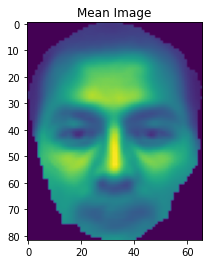

In [4]:
mu_img = np.mean(X, axis=1)
plt.imshow(mu_img.reshape((82, 66)))
plt.title("Mean Image")
plt.show()


### Q3

In [5]:
X.shape, mu_img.shape

((5412, 150), (5412,))

In [6]:
X_subtracted = X - mu_img[:, np.newaxis]
X_subtracted.shape

(5412, 150)

### Q4

In [7]:
# Compute covariance matrix using SVD for stability, also np.linalg.eig was giving complex values
# https://stackoverflow.com/questions/56736928/numpy-why-does-np-linalg-eig-and-np-linalg-svd-give-different-v-values-of-svd

U, S, Vt = np.linalg.svd(X_subtracted, full_matrices=False)
C = np.dot(X_subtracted, X_subtracted.T) / N


### Q5

In [8]:
eigenvals = S**2
eigenvecs = U

In [9]:
eigenvals

array([3.88324779e+08, 2.27716023e+08, 1.37590986e+08, 1.25517254e+08,
       4.64641240e+07, 4.23332528e+07, 3.71519298e+07, 3.18070790e+07,
       2.18189145e+07, 1.92045122e+07, 1.74334786e+07, 1.57140043e+07,
       1.24365040e+07, 1.19287989e+07, 1.01356472e+07, 9.60510100e+06,
       8.33901809e+06, 7.70634373e+06, 6.58307416e+06, 5.92354367e+06,
       5.85435284e+06, 5.30348298e+06, 5.12309731e+06, 4.73444264e+06,
       4.14415207e+06, 3.83261251e+06, 3.75212153e+06, 3.53266189e+06,
       3.18565432e+06, 2.93509412e+06, 2.86629672e+06, 2.58170664e+06,
       2.44714957e+06, 2.37134994e+06, 2.31751288e+06, 2.18526878e+06,
       2.13843944e+06, 1.98729158e+06, 1.92981109e+06, 1.89012129e+06,
       1.77135904e+06, 1.73336344e+06, 1.67511467e+06, 1.59794018e+06,
       1.55149491e+06, 1.50788346e+06, 1.46275139e+06, 1.39857267e+06,
       1.35447687e+06, 1.29507222e+06, 1.24557713e+06, 1.21750051e+06,
       1.17582631e+06, 1.15036427e+06, 1.13164198e+06, 1.08350175e+06,
      

In [10]:
eigenvecs

array([[ 4.19546139e-17, -1.41952544e-16, -1.29943300e-16, ...,
         4.98199803e-17,  3.25627173e-02,  1.19076237e-01],
       [ 2.27429562e-17,  4.20362586e-18, -5.60550682e-17, ...,
         1.05421099e-15,  1.02855899e-02,  8.70808190e-02],
       [ 5.02710832e-17,  5.13729495e-17, -2.34423915e-17, ...,
         6.78057194e-15, -1.17572508e-02,  2.34917110e-01],
       ...,
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])

### Q6

In [11]:
total_variance = np.sum(eigenvals)
variance = 0
k = 0
for eigenval in eigenvals:
    variance += eigenval
    k += 1
    if variance / total_variance >= 0.95:
        break
print(f"Number of principal components for 95% variance: {k}")

Number of principal components for 95% variance: 37


### Q7

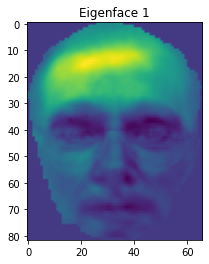

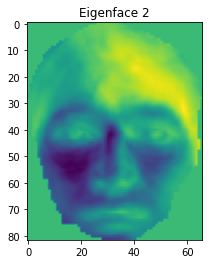

In [12]:
for i in range(2):
    plt.imshow(eigenvecs[:, i].reshape(82, 66))
    plt.title(f"Eigenface {i+1}")
    plt.show()

### Q8

In [13]:
# Project testing images into the subspace spanned by top 37 eigenvecs
V_k = eigenvecs[:, :37]
test_coords = {}
for subject, files in testing_data.items():
    test_coords[subject] = []
    for file in files:
        image = imread(file).flatten()
        image_vector = image - mu_img
        w = np.dot(V_k.T, image_vector)
        test_coords[subject].append(w)
        
# Project training images into subspace
train_coords = []
train_labels = []
for subject, files in training_data.items():
    for file in files:
        image = imread(file).flatten()
        image_vector = image - mu_img
        w = np.dot(V_k.T, image_vector)
        train_coords.append(w)
        train_labels.append(subject)

train_coords = np.array(train_coords)


### Q9

In [14]:
correct_predictions = 0
total_predictions = 0

for subject, coords_list in test_coords.items():
    for test_coord in coords_list:
        distances = cdist([test_coord], train_coords, metric='euclidean')
        closest_idx = np.argmin(distances)
        predicted_label = train_labels[closest_idx]
        
        if predicted_label == subject:
            correct_predictions += 1
        total_predictions += 1

# Calculate recognition accuracy
accuracy = (correct_predictions / total_predictions) * 100
print(f"Recognition accuracy: {accuracy}%")

Recognition accuracy: 80.0%
